# Optimisation of the SDO thresholds (PIC sweep)

The results of `PIC/sweep.dag` (one set per line of `parameters.txt`): every set has its light curve, RV, FWHM, BIS, contrast and CCF time series (`sets/<set>/`, `opt_rv/`) and its MAD / RMS against HARPS-N, SORCE/TIM and TSIS-1 (`sets/<set>/stats.json`, all in `results/sweep_stats.csv`). This notebook reads the folder of the sets (copied from PIC; path `sweep_results` of `local_paths.ini`), recomputes the statistics if needed (e.g. on another window) and makes the figures of the optimisation: heatmaps of I_th × B_sat per T_sp and I_th × T_sp per B_sat, and the RMS against every parameter.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sunsim import observations as obs, local_path

BASE = local_path('sweep_results_fraction')               # the folder 'sets' of the sweep (or its parent)
START = '2015-07-18'                             # t = 0 of the simulations
WINDOW = None                                    # e.g. ('2021-01-01', '2024-01-01'): statistics on these epochs only
RECOMPUTE = WINDOW is not None                   # recompute stats.json of every set (the observations are needed)

In [2]:
if RECOMPUTE:
    import glob, json, os
    harps = obs.load_harpsn(local_path('harpsn_sun'), START)
    sorce, tsis = obs.load_sorce(local_path('sorce_tsi'), START), obs.load_tsis(local_path('tsis_tsi'), START)
    cuts = obs.load_interventions(local_path('harpsn_interventions'), START)
    for f in sorted(glob.glob(os.path.join(str(BASE), '**', 'stats.json'), recursive=True)):
        params = {k: v for k, v in json.load(open(f)).items() if k in ('noise_th', 'I_th', 'B_sat', 'T_sp')}
        obs.sweep_stats(os.path.dirname(f), START, harps, sorce, tsis, cuts, window=WINDOW, params=params)

df = obs.load_sweep_stats(BASE)
print(len(df), 'sets')
for value, unit in (('rv_rms', 'm/s'), ('rv_mad', 'm/s'), ('sorce_rms', 'ppm'), ('tsis_rms', 'ppm')):
    if value in df and df[value].notna().any():
        b = obs.best_sets(df, value, 1).iloc[0]
        print('best %-9s %.4g %s: T_sp = %g, noise_th = %g, I_th = %g, B_sat = %g (range %.4g -> %.4g)'
              % (value, b[value], unit, b['T_sp'], b['noise_th'], b['I_th'], b['B_sat'], df[value].min(), df[value].max()))
obs.best_sets(df, 'rv_rms', 10)[['T_sp', 'noise_th', 'I_th', 'B_sat', 'rv_rms', 'rv_mad', 'sorce_rms', 'tsis_rms']]

231 sets
best rv_rms    0.8395 m/s: T_sp = 1100, noise_th = 8, I_th = 0.95, B_sat = 25 (range 0.8395 -> 1.239)
best rv_mad    0.5261 m/s: T_sp = 1100, noise_th = 8, I_th = 0.95, B_sat = 25 (range 0.5261 -> 0.6628)
best sorce_rms 161 ppm: T_sp = 300, noise_th = 8, I_th = 0.75, B_sat = 200 (range 161 -> 682.6)
best tsis_rms  135.5 ppm: T_sp = 600, noise_th = 8, I_th = 0.75, B_sat = 50 (range 135.5 -> 1584)


,T_sp,noise_th,I_th,B_sat,rv_rms,rv_mad,sorce_rms,tsis_rms
180,1100.0,8.0,0.95,25.0,0.839544,0.526146,402.129408,712.977465
195,1100.0,8.0,0.95,8.0,0.839545,0.526159,402.129295,712.976882
165,1100.0,8.0,0.95,10.0,0.839545,0.526159,402.129295,712.976882
171,1100.0,8.0,0.95,15.0,0.839545,0.526159,402.129295,712.976882
174,1100.0,8.0,0.95,20.0,0.839545,0.526159,402.129295,712.976882
182,600.0,8.0,0.95,25.0,0.840826,0.529580,268.562427,406.521954
176,600.0,8.0,0.95,20.0,0.840827,0.529644,268.562336,406.521399
167,600.0,8.0,0.95,10.0,0.840827,0.529644,268.562336,406.521399
173,600.0,8.0,0.95,15.0,0.840827,0.529644,268.562336,406.521399
197,600.0,8.0,0.95,8.0,0.840827,0.529644,268.562336,406.521399


## RV against HARPS-N

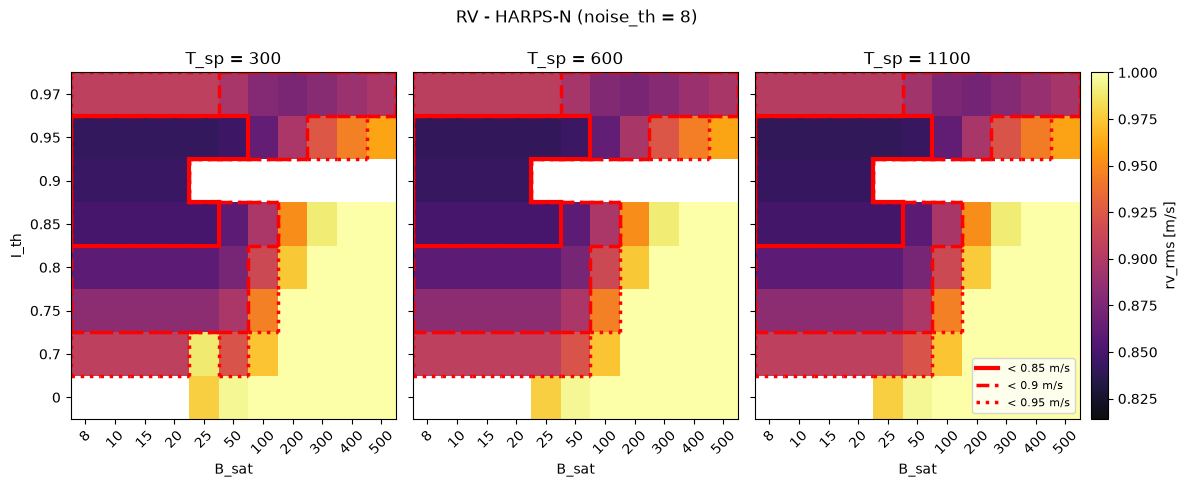

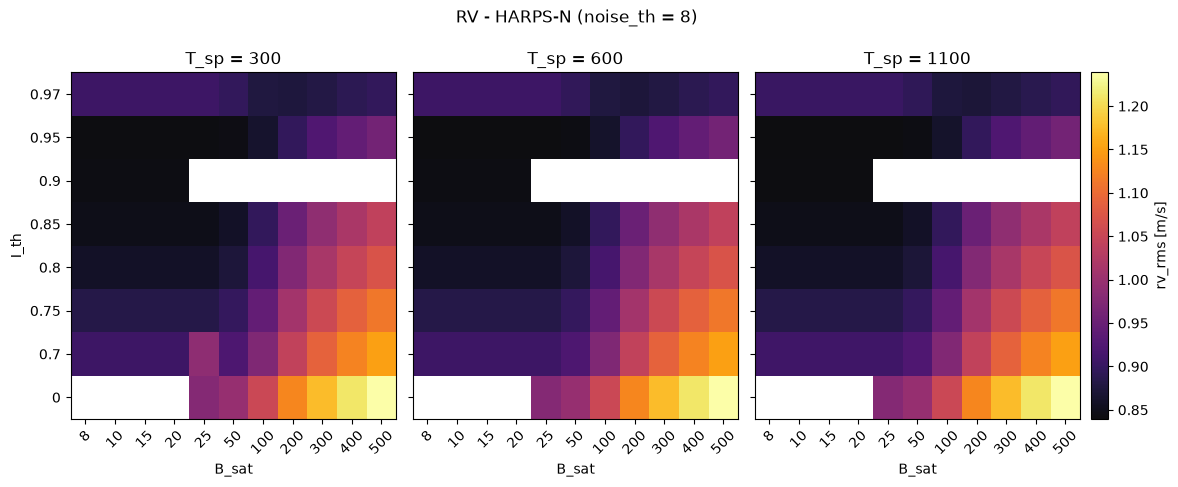

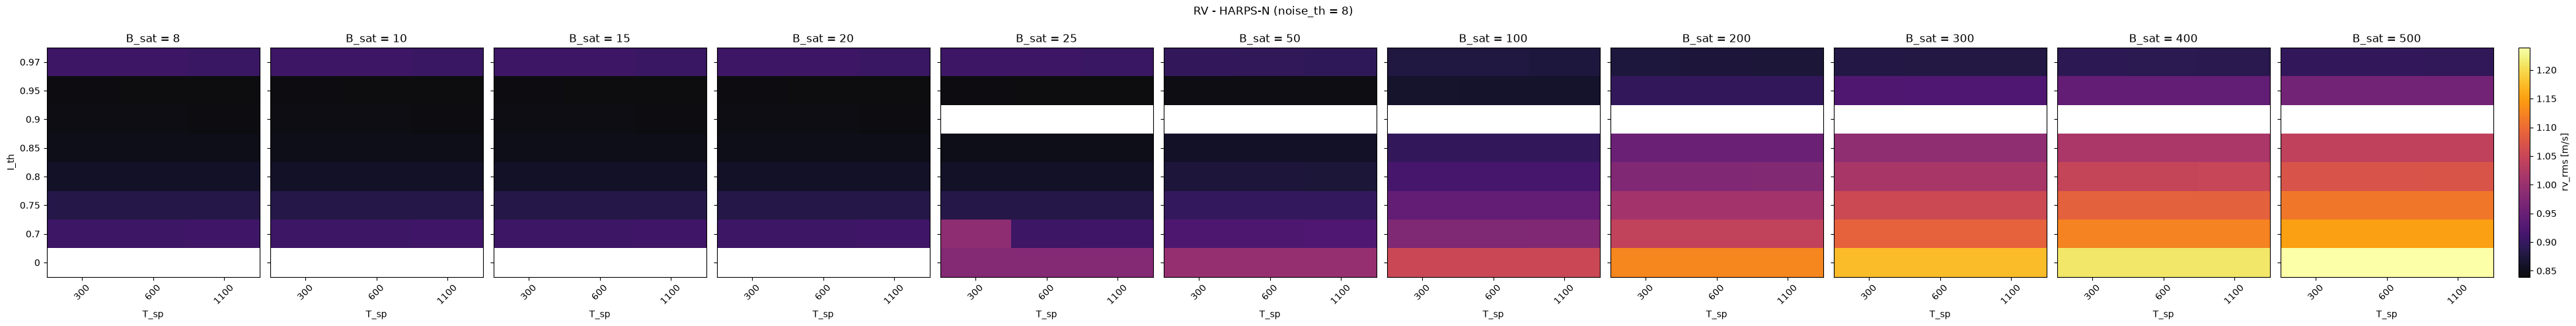

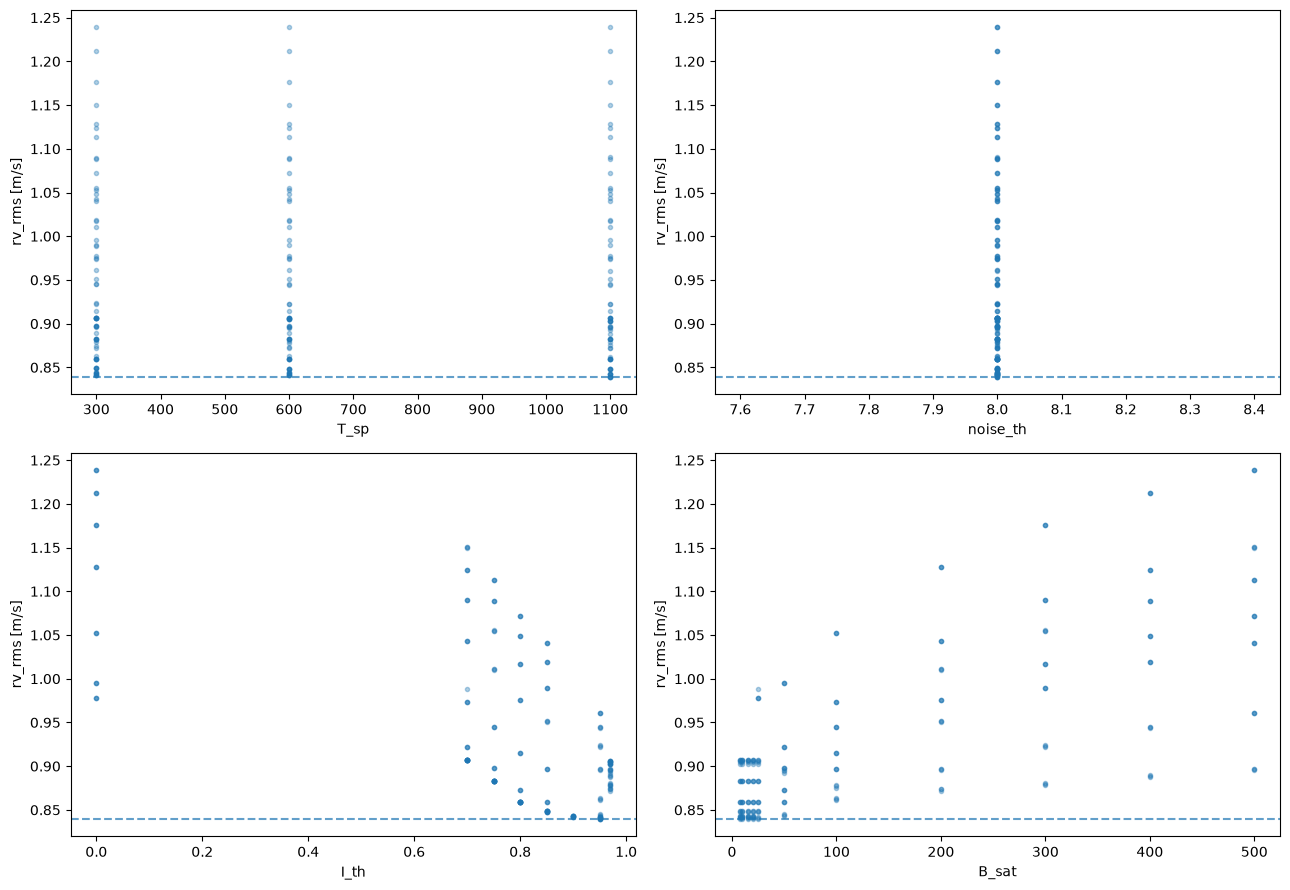

In [3]:
for noise in sorted(df['noise_th'].unique()):
    obs.plot_sweep_heatmaps(df, 'rv_rms', 'B_sat', 'I_th', 'T_sp', fixed={'noise_th': noise}, levels=[0.85, 0.90, 0.95],
                            unit='m/s', title='RV - HARPS-N (noise_th = %g)' % noise)
    for ax in plt.gcf().axes:
        for im in ax.images:
            im.set_clim(0.8141, 1)
    plt.show()
    
    obs.plot_sweep_heatmaps(df, 'rv_rms', 'B_sat', 'I_th', 'T_sp', fixed={'noise_th': noise},
                            unit='m/s', title='RV - HARPS-N (noise_th = %g)' % noise)
    plt.show()
    obs.plot_sweep_heatmaps(df, 'rv_rms', 'T_sp', 'I_th', 'B_sat', fixed={'noise_th': noise}, unit='m/s',
                            title='RV - HARPS-N (noise_th = %g)' % noise)
    plt.show()
obs.plot_sweep_parameters(df, 'rv_rms', unit='m/s')
plt.show()

## TSI against SORCE/TIM and TSIS-1

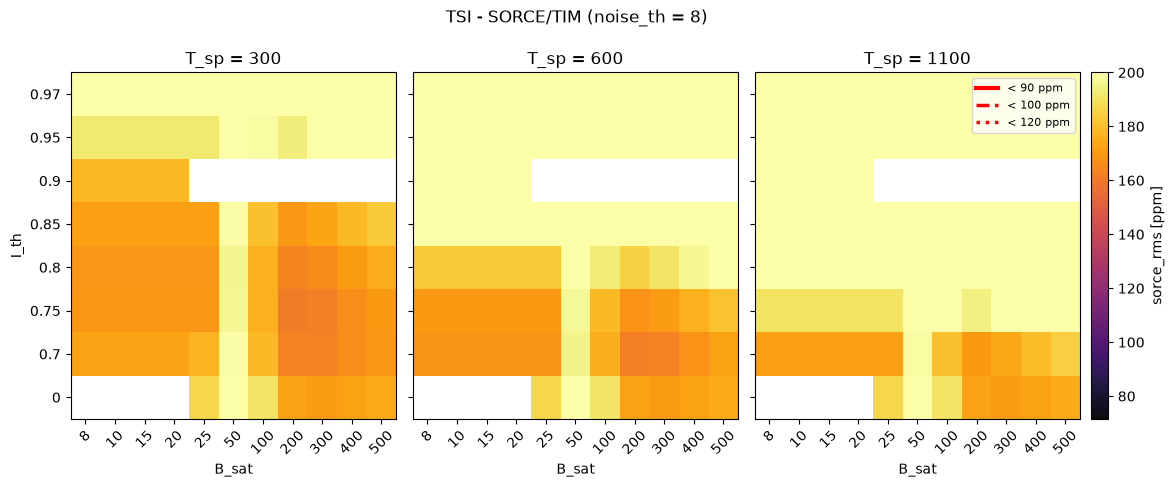

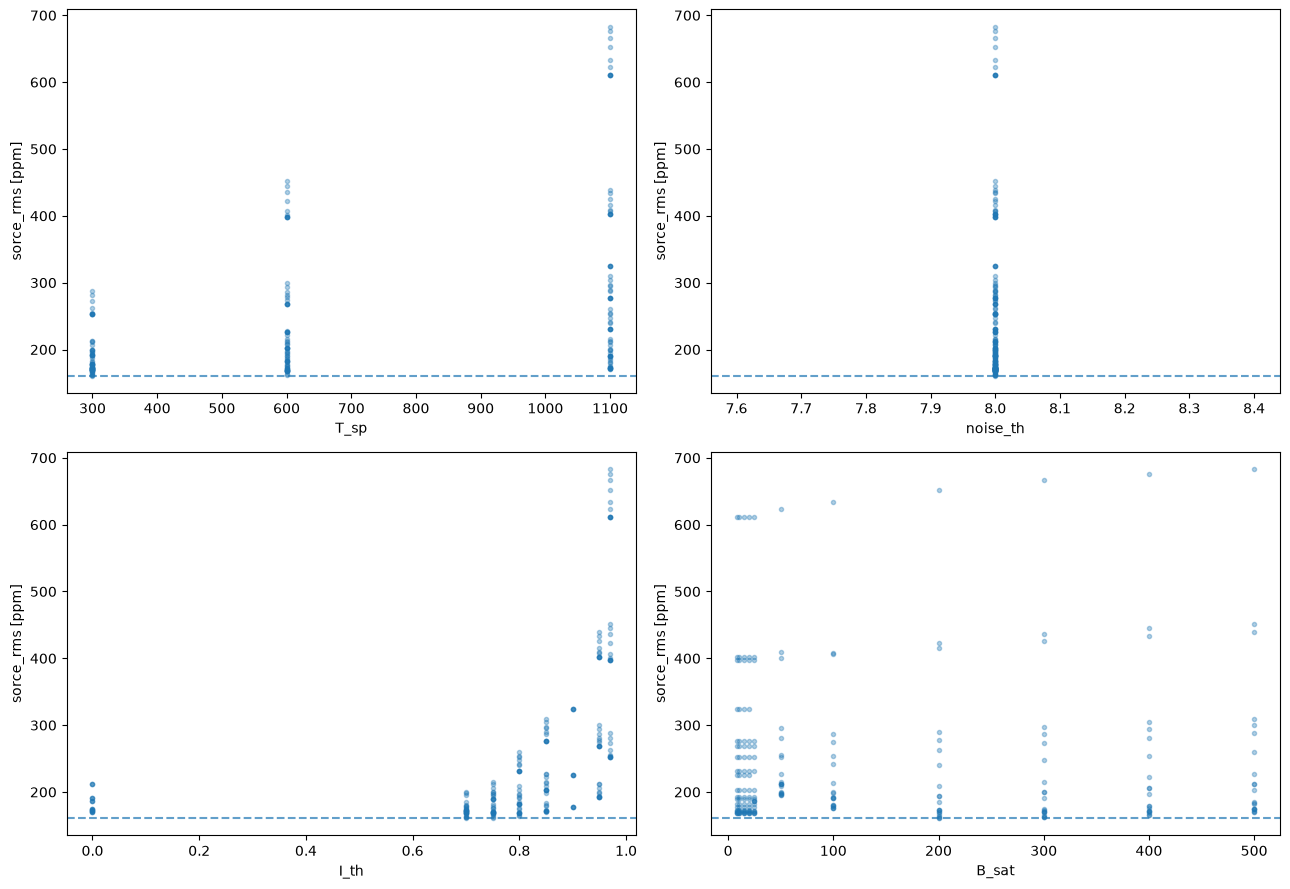

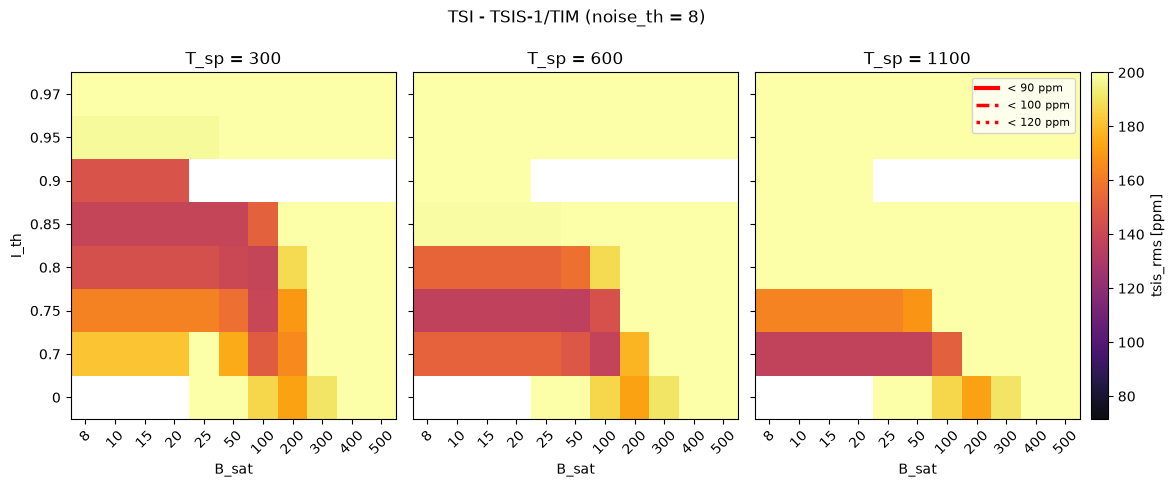

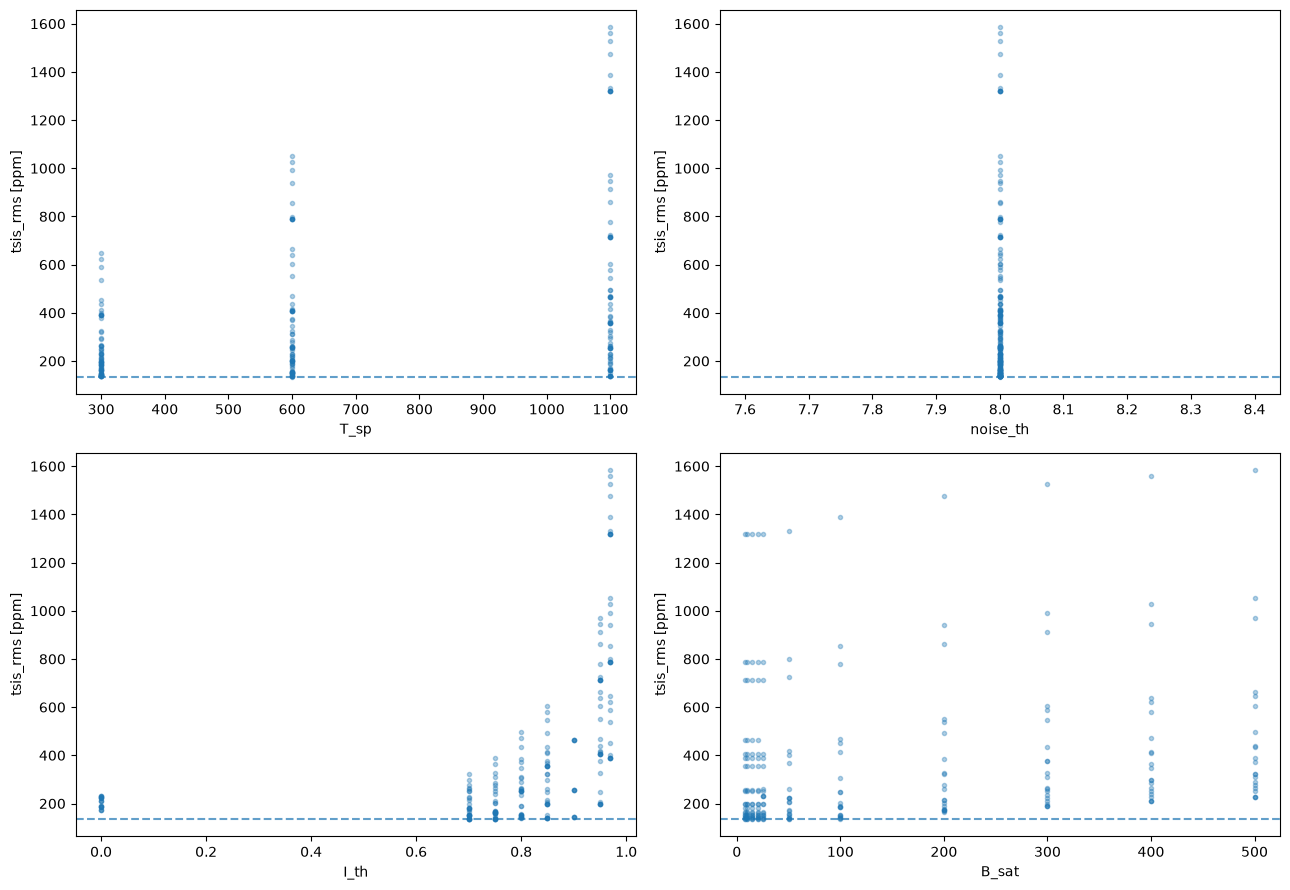

In [4]:
for value, title in (('sorce_rms', 'TSI - SORCE/TIM'), ('tsis_rms', 'TSI - TSIS-1/TIM')):
    if value not in df or df[value].isna().all():
        continue
    for noise in sorted(df['noise_th'].unique()):
        obs.plot_sweep_heatmaps(df, value, 'B_sat', 'I_th', 'T_sp', fixed={'noise_th': noise}, levels=[90, 100, 120],
                                unit='ppm', title='%s (noise_th = %g)' % (title, noise))
        for ax in plt.gcf().axes:
            for im in ax.images:
                im.set_clim(71.55, 200)
        plt.show()
    obs.plot_sweep_parameters(df, value, unit='ppm')
    plt.show()